 //explicacion del dataset y grupo  

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

// Importacion del data set

In [42]:
dataset = pd.read_csv('../../dataset/listings.csv')
dataset.info(verbose=True, show_counts=True)
type(dataset)

<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  str    
 9   host_id                                       29685 non-null  int64  
 1

pandas.DataFrame

In [53]:
nulos = dataset[['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood','neighbourhood_group_cleansed', 'calendar_updated', 'instant_bookable']]
nulos.head(15)
#"host_since", "host_response_time", "host_response_rate", "host_acceptance_rate", "host_thumbnail_url", "host_neighbourhood", "host_total_listings_count", "host_verifications neighbourhood","neighbourhood_group_cleansed", "calendar_updated", "instant_bookable"

,neighborhood_overview,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_thumbnail_url,host_neighbourhood,host_total_listings_count,host_verifications,neighbourhood,neighbourhood_group_cleansed,calendar_updated,instant_bookable
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


a priori vemos que las siguientes variables no presentan valores, es decir, estan vacías (codigo de abajo).


In [13]:

vacias = dataset.columns[dataset.isna().all()]
print(len(vacias), "columnas vacías:")
for col in vacias:
    print("-", col)

13 columnas vacías:
- neighborhood_overview
- host_since
- host_response_time
- host_response_rate
- host_acceptance_rate
- host_thumbnail_url
- host_neighbourhood
- host_total_listings_count
- host_verifications
- neighbourhood
- neighbourhood_group_cleansed
- calendar_updated
- instant_bookable


//introducción, mostrar tablas y contar que se borra y la tabla desp de la limpieza. 
Empezamos por las columnas vacias

In [54]:
dataset_limpio = dataset.drop(columns=vacias)
print(dataset.shape, "->", dataset_limpio.shape)
print("\n")
dataset_limpio.info()

(29685, 90) -> (29685, 77)


<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   picture_url                                   29684 non-null  str    
 8   host_id                                       29685 non-null  int64  
 9   host_url                                   

In [15]:
dataset_limpio.describe() #describe no toma en cuenta los string, por eso las 48 cols

,id,scrape_id,host_id,host_profile_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_listings_count,latitude,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,2.968500e+04,2.968500e+04,2.968500e+04,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,...,25957.000000,25957.000000,25957.000000,25957.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,25957.000000
mean,9.329954e+17,2.026063e+13,1.081103e+16,1.476728e+18,7.506687,5.532727,5.323362,5.461142,19.602964,-34.592114,...,4.742028,4.869180,4.862890,4.874793,4.740904,15.194240,14.214654,0.701937,0.057773,1.481166
std,5.838355e+17,0.000000e+00,1.347071e+17,3.962312e+16,4.083517,3.376887,4.046868,3.296444,44.760560,0.017920,...,0.371037,0.291209,0.304637,0.244150,0.375315,32.782011,32.632849,3.608907,0.735822,1.640487
min,1.150800e+04,2.026063e+13,1.342600e+04,1.462507e+18,0.000000,0.000000,0.000000,0.000000,0.000000,-34.690056,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,6.233293e+17,2.026063e+13,3.506745e+07,1.462945e+18,4.000000,3.000000,2.000000,3.000000,1.000000,-34.603396,...,4.670000,4.850000,4.850000,4.850000,4.680000,1.000000,1.000000,0.000000,0.000000,0.370000
50%,1.046350e+18,2.026063e+13,1.585246e+08,1.467135e+18,8.000000,5.000000,4.000000,5.000000,3.000000,-34.591459,...,4.830000,4.950000,4.950000,4.940000,4.830000,3.000000,2.000000,0.000000,0.000000,0.980000
75%,1.431417e+18,2.026063e+13,4.644293e+08,1.470093e+18,11.000000,8.000000,8.000000,8.000000,16.000000,-34.581430,...,4.950000,5.000000,5.000000,5.000000,4.940000,12.000000,10.000000,0.000000,0.000000,2.050000
max,1.717830e+18,2.026063e+13,1.716955e+18,1.716967e+18,17.000000,11.000000,15.000000,11.000000,1375.000000,-34.534980,...,5.000000,5.000000,5.000000,5.000000,5.000000,208.000000,208.000000,52.000000,18.000000,41.660000


In [16]:
dataset_limpio.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,54019695,https://www.airbnb.com/rooms/54019695,20260629030533,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,https://a0.muscache.com/pictures/miso/Hosting-...,298874610,https://www.airbnb.com/users/show/298874610,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
1,41720307,https://www.airbnb.com/rooms/41720307,20260629030533,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,https://a0.muscache.com/pictures/37e687e2-2587...,220409424,https://www.airbnb.com/users/show/220409424,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
2,1090530711732696379,https://www.airbnb.com/rooms/1090530711732696379,20260629030533,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,https://a0.muscache.com/pictures/3adbe27a-af59...,488443857,https://www.airbnb.com/users/show/488443857,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
3,1482653002662185299,https://www.airbnb.com/rooms/1482653002662185299,20260629030533,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",https://a0.muscache.com/pictures/hosting/Hosti...,283840529,https://www.airbnb.com/users/show/283840529,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
4,1046394538968941382,https://www.airbnb.com/rooms/1046394538968941382,20260629030533,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,https://a0.muscache.com/pictures/hosting/Hosti...,550970409,https://www.airbnb.com/users/show/550970409,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


Ahora siguen las variables que no nos dicen nada.


In [17]:
por_host = dataset_limpio.groupby("host_has_profile_pic")["host_id"].nunique()
porcentaje = (por_host / por_host.sum() * 100).round(1)

display(pd.DataFrame({"hosts": por_host, "%": porcentaje}))



,hosts,%
host_has_profile_pic,,
f,826,5.7
t,13730,94.3


Con esto vemos que la variable (host_has_profile_pic) no contiene informacion relevante, por eso puede ser borrada.

In [18]:
scrape = dataset_limpio["scrape_id"].nunique()
scrape

1

 Vemos que con la variable scrape id, no tenemos info relevante (ya que hay un unico scrapeo de los datos)

In [55]:
dataset_limpio = dataset_limpio.set_index("id")
a_borrar = ["listing_url", "scrape_id", "picture_url", "host_url",
            "host_picture_url", "host_has_profile_pic", "host_thumbnail_url"]

ya_borradas = [c for c in a_borrar if c not in dataset_limpio.columns]
print("Ya no estaban:", ya_borradas)

dataset_limpio = dataset_limpio.drop(columns=[c for c in a_borrar if c in dataset_limpio.columns])
print(dataset_limpio.shape)
dataset_limpio

Ya no estaban: ['host_thumbnail_url']
(29685, 70)


,last_scraped,source,name,description,host_id,host_profile_id,host_profile_url,host_name,hosts_time_as_user_years,hosts_time_as_user_months,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
id,,,,,,,,,,,,,,,,,,,,,
54019695,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,298874610,1469536348265366895,https://www.airbnb.com/users/profile/146953634...,Pablo,6,9,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
41720307,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,220409424,1463206751662853765,https://www.airbnb.com/users/profile/146320675...,Monica,7,8,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
1090530711732696379,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,488443857,1470198261120530992,https://www.airbnb.com/users/profile/147019826...,Mathi,3,7,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
1482653002662185299,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",283840529,1469486631712739967,https://www.airbnb.com/users/profile/146948663...,Liliana,6,10,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
1046394538968941382,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,550970409,1470463634022740655,https://www.airbnb.com/users/profile/147046363...,Braian,2,6,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994022693284854325,2026-07-02,previous scrape,Lumiere Fair apparemment,Lumiere Fair has a modern and bright design th...,124702396,1468258412487155546,https://www.airbnb.com/users/profile/146825841...,Nancy,9,2,...,4.86,4.43,4.71,4.86,NaN,3,3,0,0,0.21
1016061449243279308,2026-07-02,previous scrape,Charming Modern Studio in Caballito,Bright and stylish modern studio in the heart ...,344599,1462516210018566099,https://www.airbnb.com/users/profile/146251621...,Welcome BA,15,5,...,4.90,4.85,4.90,4.84,NaN,31,31,0,0,2.85
1055203909942066000,2026-07-02,previous scrape,Lovely Moldes,"Kick back and relax in this calm, stylish space.",552774318,1470470371718015421,https://www.airbnb.com/users/profile/147047037...,Jorge Enrique,2,6,...,4.91,4.94,4.97,4.94,NaN,1,1,0,0,1.14


In [59]:
print(dataset_limpio.isna().sum())

last_scraped                                       0
source                                             0
name                                               0
description                                      768
host_id                                            0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               3728
Length: 70, dtype: int64


In [60]:
dataset_limpio["description"].value_counts()

description
Keep it simple at this peaceful and centrally-located place.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 148
MOT is the leading agency for short term rentals in Buenos Aires and Mendoza. We also offer amazing monthly deals for long term stays. Contact us for further information!                                                                                                                                                                                                                                                                 

Vemos que quiza las descripciones no nos dicen muchos, aunque las podriamos utilizar para conocer que cantidad de publicaciones tienen descripcio vs. las que no

In [79]:
dataset_limpio["minimum_nights"].describe()

count    29682.000000
mean         4.951722
std         18.114840
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        730.000000
Name: minimum_nights, dtype: float64

In [80]:
dataset_limpio["room_type"].value_counts()

room_type
Entire home/apt    26790
Private room        2616
Hotel room           141
Shared room          138
Name: count, dtype: int64

// depuracion de la base (variables no utilizables,columnas enteramente nulas..)

//UNIVARIADAS 

### Para comenzar la validacion de las Hipotesis A y B, primero vamos, por cada una de ellas, a mirar como se comporta la muestra, utilizando distintas herramientos tanto analiticas como graficas.

### Analisis de la hipotesis A (Mas del 60% de la oferta es controlada por agencias multipropiedad, no por personas alquilando su propio hogar)

In [92]:
dfA=dataset_limpio["host_id"]

In [94]:
cuenta = dfA.value_counts()
filtered = cuenta[cuenta > 1]
print("Multipropiedad: ", filtered.count(), "Personales: ", cuenta.count()-filtered.count())

Multipropiedad:  3748 Personales:  10808


De entrada, vemos que la cantidad de listadores con mas de 1 propiedad en dispocicion es casi un tercio de las propiedaes alquiladas por sus propios dueños.

/tmp/ipykernel_7763/1436527015.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(filtered.values, vert=False)


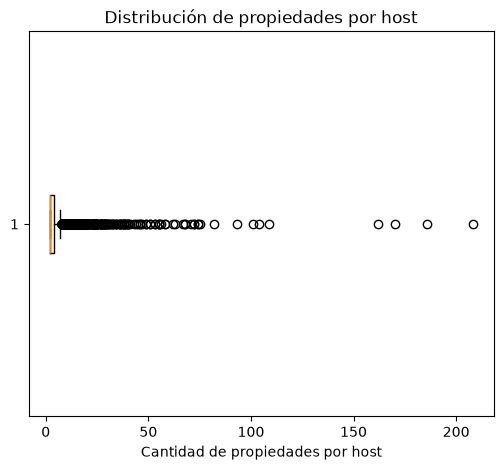

In [ ]:
# Porcentaje de publicaciones según si el anfitrión ofrece más de un alojamiento
cuenta = dfA.value_counts()
publicaciones = pd.Series({
    "Anfitrión con 1 alojamiento": cuenta[cuenta == 1].sum(),
    "Anfitrión con múltiples alojamientos": cuenta[cuenta > 1].sum(),
})
porcentaje_publicaciones = publicaciones / publicaciones.sum() * 100

ax = porcentaje_publicaciones.plot(kind="bar", figsize=(8, 5), color=["#7aa6c2", "#e07a5f"])
ax.axhline(60, color="black", linestyle="--", linewidth=1.5, label="Umbral de hipótesis: 60%")
ax.set_title("Distribución de publicaciones por tipo de anfitrión")
ax.set_xlabel("")
ax.set_ylabel("Porcentaje de publicaciones (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend()

for barra, valor in zip(ax.patches, porcentaje_publicaciones):
    ax.annotate(f"{valor:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")

plt.tight_layout()
plt.show()

//BIVARIADAS

//MULTIVARIADAS